In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "underactuated[all]>=2026.9.8"

In [2]:
import mpld3
import numpy as np
from IPython.display import display
from matplotlib import pyplot as plt
from pydrake.all import PiecewisePolynomial, ZmpPlanner

from underactuated import running_as_notebook

if running_as_notebook:
    mpld3.enable_notebook()

# Example 5.1: The ZMP Planner

This example shows how Drake's `ZmpPlanner` turns a desired zero-moment point (ZMP) trajectory into a center-of-mass (CoM) trajectory for the linear inverted pendulum model (LIPM).

For a CoM at constant height $z$, the horizontal dynamics are
$$
\ddot{\mathbf{c}} = \frac{g}{z}\left(\mathbf{c} - \mathbf{y}\right),
$$
where $\mathbf{c}=(x,y)$ is the CoM position and $\mathbf{y}$ is the ZMP (equal to the center of pressure on flat ground).  The ZMP must stay inside the support polygon, so a footstep plan defines a feasible ZMP trajectory.  Given a desired ZMP trajectory $\mathbf{y}_d(t)$, `ZmpPlanner` minimizes
$$
\int_0^{t_f}\left[\|\mathbf{y}(t)-\mathbf{y}_d(t)\|_{Q_y}^2 + \|\ddot{\mathbf{c}}(t)\|_R^2\right]dt
$$
and also returns a time-varying feedback policy on the CoM state.  Try changing the footstep timing below and see how the CoM trajectory reacts.

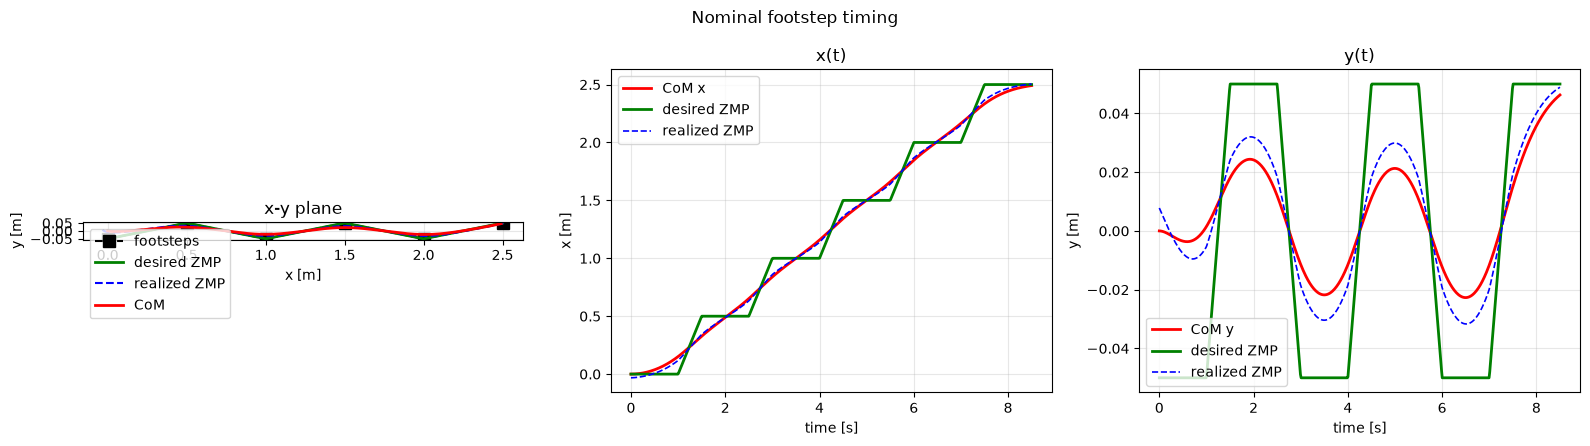

Plan duration: 8.50 s
Peak |com_y|: 0.0463 m
Max |ZMP tracking error|: 1.5781e-01 m


In [3]:
def GenerateDesiredZmpTraj(
    footsteps: np.typing.NDArray,
    double_support_duration: float,
    single_support_duration: float,
) -> PiecewisePolynomial:
    """Computes a desired ZMP trajectory from a sequence of footsteps.

    Args:
        footsteps: An array of shape (n, 2) where n is the number of footsteps.
        double_support_duration: The duration of the double support phase.
        single_support_duration: The duration of the single support phase.
    """
    time_steps = []
    zmp_d = []

    time = 0

    time_steps.append(time)
    zmp_d.append(footsteps[0])
    time += single_support_duration
    time_steps.append(time)
    zmp_d.append(footsteps[0])

    for i in range(1, len(footsteps)):
        time += double_support_duration
        time_steps.append(time)
        zmp_d.append(footsteps[i])

        time += single_support_duration
        time_steps.append(time)
        zmp_d.append(footsteps[i])

    zmp_d = np.array(zmp_d).T

    # First-order hold gives a piecewise-linear ZMP trajectory.
    zmp_traj = PiecewisePolynomial.FirstOrderHold(time_steps, zmp_d)

    return zmp_traj


def plan_walk(
    footsteps,
    double_support_duration,
    single_support_duration,
    height=1.0,
    x0=None,
):
    """Builds the desired ZMP trajectory and calls Drake's ZmpPlanner."""
    if x0 is None:
        x0 = np.zeros(4)  # CoM position and velocity, both zero
    zmp_traj = GenerateDesiredZmpTraj(
        footsteps, double_support_duration, single_support_duration
    )
    zmp_planner = ZmpPlanner()
    zmp_planner.Plan(zmp_traj, x0, height)
    return zmp_planner, zmp_traj


def evaluate_plan(zmp_planner, zmp_traj, height, n_samples=600):
    """Evaluates the CoM trajectory, acceleration, and realized ZMP."""
    ts = np.linspace(0.0, zmp_traj.end_time(), n_samples)
    com, comd, comdd, zmp = [], [], [], []
    for t in ts:
        c = zmp_planner.get_nominal_com(t)
        cd = zmp_planner.get_nominal_comd(t)
        x = np.concatenate((c, cd))
        cdd = zmp_planner.ComputeOptimalCoMdd(t, x)
        com.append(c)
        comd.append(cd)
        comdd.append(cdd)
        zmp.append(zmp_planner.comdd_to_cop(x, cdd))
    return (
        ts,
        np.array(com),
        np.array(comd),
        np.array(comdd),
        np.array(zmp),
    )


def plot_plan(footsteps, zmp_planner, zmp_traj, height, title=None):
    ts, com, comd, comdd, zmp = evaluate_plan(zmp_planner, zmp_traj, height)
    zmp_d = np.array([zmp_planner.get_desired_zmp(t) for t in ts])

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    ax = axes[0]
    ax.plot(footsteps[:, 0], footsteps[:, 1], "ks--", ms=8, label="footsteps")
    ax.plot(zmp_d[:, 0], zmp_d[:, 1], "g-", lw=2, label="desired ZMP")
    ax.plot(zmp[:, 0], zmp[:, 1], "b--", lw=1.5, label="realized ZMP")
    ax.plot(com[:, 0], com[:, 1], "r-", lw=2, label="CoM")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="best")
    ax.set_title("x-y plane")

    for k, (ax, label) in enumerate(zip(axes[1:], ["x", "y"])):
        ax.plot(ts, com[:, k], "r-", lw=2, label=f"CoM {label}")
        ax.plot(ts, zmp_d[:, k], "g-", lw=2, label="desired ZMP")
        ax.plot(ts, zmp[:, k], "b--", lw=1.2, label="realized ZMP")
        ax.set_xlabel("time [s]")
        ax.set_ylabel(f"{label} [m]")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best")
        ax.set_title(f"{label}(t)")

    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig, ts, com, zmp, zmp_d


# An average human stride is about 0.7 m, and the width between feet is
# about 0.1 m.
footsteps = np.array(
    [[0, -0.05], [0.5, 0.05], [1, -0.05], [1.5, 0.05], [2, -0.05], [2.5, 0.05]]
)
height = 1.0

zmp_planner, zmp_traj = plan_walk(
    footsteps, double_support_duration=0.5, single_support_duration=1.0
)
fig, ts, com, zmp, zmp_d = plot_plan(
    footsteps, zmp_planner, zmp_traj, height, title="Nominal footstep timing"
)
plt.show()

print(f"Plan duration: {zmp_traj.end_time():.2f} s")
print(f"Peak |com_y|: {np.max(np.abs(com[:, 1])):.4f} m")
print(f"Max |ZMP tracking error|: "
      f"{np.max(np.linalg.norm(zmp - zmp_d, axis=1)):.4e} m")

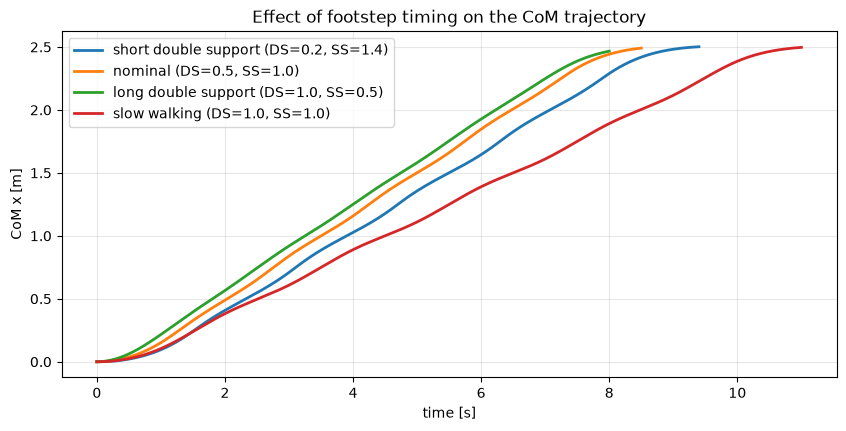

 DS [s]  SS [s]   T [s]   peak|y|    ZMP err  final x
   0.20    1.40    9.40    0.0491   2.05e-01   2.5018
   0.50    1.00    8.50    0.0463   1.58e-01   2.4913
   1.00    0.50    8.00    0.0410   9.67e-02   2.4669
   1.00    1.00   11.00    0.0486   1.02e-01   2.4968


In [4]:
# Change the timing of the steps.  The double-support duration is the time
# the ZMP spends moving between two foot centres; the single-support duration
# is the time it stays at a foot centre.
timings = [
    (0.2, 1.4, "short double support"),
    (0.5, 1.0, "nominal"),
    (1.0, 0.5, "long double support"),
    (1.0, 1.0, "slow walking"),
]

fig, ax = plt.subplots(figsize=(10, 4.5))
rows = []
for ds, ss, label in timings:
    planner, traj = plan_walk(footsteps, ds, ss)
    _, com_i, _, _, zmp_i = evaluate_plan(planner, traj, height)
    t_i = np.linspace(0, traj.end_time(), com_i.shape[0])
    zmp_d_i = np.array([planner.get_desired_zmp(t) for t in t_i])
    ax.plot(t_i, com_i[:, 0], lw=2, label=f"{label} (DS={ds}, SS={ss})")
    rows.append([
        ds,
        ss,
        traj.end_time(),
        np.max(np.abs(com_i[:, 1])),
        np.max(np.linalg.norm(zmp_i - zmp_d_i, axis=1)),
        com_i[-1, 0],
    ])

ax.set_xlabel("time [s]")
ax.set_ylabel("CoM x [m]")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
ax.set_title("Effect of footstep timing on the CoM trajectory")
plt.show()

print(f"{'DS [s]':>7} {'SS [s]':>7} {'T [s]':>7} {'peak|y|':>9} "
      f"{'ZMP err':>10} {'final x':>8}")
for r in rows:
    print(f"{r[0]:7.2f} {r[1]:7.2f} {r[2]:7.2f} {r[3]:9.4f} "
          f"{r[4]:10.2e} {r[5]:8.4f}")